# β-VAE (Higgins et al., ICLR 2017): reproducing Figure 7A and 7B on dSprites

This notebook trains the two models compared in **Figure 7A** (β-VAE, β = 4) and **Figure 7B** (plain VAE, β = 1)
on the 2D-shapes dataset (dSprites). It then runs the analyses that produce each row of the figure.

**Experimental conditions taken from the paper (Table 1, Sec. 4.2, Fig. 7 caption)**

| | Paper | This notebook |
|---|---|---|
| Data | 737,280 binary 64×64 images: shape (3) × scale (6) × rotation (40) × pos X (32) × pos Y (32) | dSprites (same factor grid) |
| Encoder | FC 1200-1200, ReLU, outputs a diagonal Gaussian q(z\|x) | same |
| Latents | 10, prior N(0, I) | same |
| Decoder | FC 1200-1200-1200-4096, Tanh, Bernoulli likelihood | same (Bernoulli logits, summed over pixels) |
| Optimiser | Adagrad, lr 1e-2 | same |
| Objective | E[log p(x\|z)] − β·KL(q(z\|x)‖p(z)) | same, β = 4 (A) and β = 1 (B), unnormalised β |
| Not specified in paper | batch size, number of updates | batch 64, 300k updates (configurable below) |

**What each row of the figure shows (computed exactly as described in the caption)**
* Columns are latents ordered by their **mean learnt posterior variance** (the last row), smallest first. The 5 most
  informative latents are shown, plus the least informative one (labelled *unused* when σ² ≈ 1).
* Row 1 (position): mean of the posterior mean μ_i as a function of the 32×32 positions, averaged over shapes, scales and rotations (jet colour map, red = high).
* Row 2 (scale): mean μ_i vs. scale, averaged over rotations and positions, one line per shape.
* Row 3 (rotation): mean μ_i vs. rotation, averaged over scales and positions, one line per shape.
  Colours follow the paper: **square = red, oval = green, heart = blue**.
* Rows 4-8: decoder output when traversing one latent over [-3, 3] (prior s.d. units) while the other 9 latents stay fixed at
  the posterior mean of one seed image.
* Last row: mean posterior variance, plus an automatic label naming the generative factor(s) each latent responds to. The paper
  labelled its columns by eye; here a variance decomposition makes the label (see Section 5).

The notebook also computes the paper's **disentanglement metric** (Sec. 3 / App. A.4) for every trained run. The paper reports
99.23% (β = 4) vs 61.58% (β = 1). The metric checks that a run reached the regime the figure illustrates, and it selects which seed
to plot. The paper trained several replicas per setting and discarded the worst 50%, because disentangling is seed-dependent and some runs diverge.

**Kaggle setup:** Accelerator = GPU (T4 or P100). Internet = On, so dSprites can be downloaded. If Internet is off,
attach any Kaggle dataset that contains `dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz`; the loader searches `/kaggle/input`.
On a T4, each 300k-step run should take roughly 10-20 minutes. The default 2 seeds × 2 β values is about 4 runs.
Checkpoints are saved to the output directory, and the notebook skips training for runs that already have one.

In [1]:
import os, glob, time, math, json, urllib.request
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib import gridspec

CFG = dict(
    betas={"A": 4.0, "B": 1.0},   # Fig. 7A: beta-VAE (beta=4); Fig. 7B: VAE (beta=1)
    latent_dim=10,
    batch_size=64,
    lr=1e-2,                      # Adagrad, Table 1
    iters=300_000,                # gradient updates per run (not given in the paper)
    n_seeds=2,                    # replicas per beta; the figure shows the best replica by the disentanglement metric
    base_seed=0,
    log_every=10_000,
    n_show=5,                     # informative latents shown per panel (+1 'least informative' column, as in the paper)
    traversal_values=[3.0, 1.5, 0.0, -1.5, -3.0],   # rows 4-8: from +3 (top) to -3 (bottom), as in the figure
    # seed image for the traversals, given as factor indices (shape, scale, rotation, posX, posY)
    # shape: 0=square, 1=ellipse/oval, 2=heart
    seed_image_factors=(2, 3, 5, 16, 10),
    metric_eval_repeats=3,        # App. A.4: each model is evaluated 3x (here: 3 independent draws of metric data)
)

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./outputs"
os.makedirs(OUT_DIR, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEVICE, "| torch", torch.__version__, "| outputs ->", OUT_DIR)
if DEVICE.type == "cpu":
    print("WARNING: no GPU found. Training at the default settings will be very slow; enable a GPU accelerator.")

device: cuda | torch 2.11.0+cu128 | outputs -> /kaggle/working


## 1. Data: dSprites
The dataset is the full Cartesian product of the generative factors. Image `i` therefore has factor indices
`np.unravel_index(i, (3, 6, 40, 32, 32))`, and the loader asserts this. The analyses rely on that layout so they can
average posterior means over exact factor sub-grids.

In [2]:
FACTOR_NAMES = ["shape", "scale", "rotation", "pos. X", "pos. Y"]
FACTOR_SIZES = (3, 6, 40, 32, 32)
SHAPE_NAMES = ["square", "oval", "heart"]
SHAPE_COLORS = ["red", "green", "blue"]          # Fig. 7 caption: square red, oval green, heart blue
N_IMAGES = int(np.prod(FACTOR_SIZES))

In [3]:
DSPRITES_FILE = "dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz"
DSPRITES_URL = ("https://github.com/google-deepmind/dsprites-dataset/raw/master/" + DSPRITES_FILE)

def locate_dsprites():
    hits = glob.glob(f"/kaggle/input/**/{DSPRITES_FILE}", recursive=True)
    hits += glob.glob(f"./**/{DSPRITES_FILE}", recursive=True)
    if hits:
        return hits[0]
    dst = os.path.join(OUT_DIR, DSPRITES_FILE)
    if not os.path.exists(dst):
        print("downloading dSprites from", DSPRITES_URL)
        urllib.request.urlretrieve(DSPRITES_URL, dst)
    return dst

path = locate_dsprites()
print("dSprites:", path)
with np.load(path, allow_pickle=True, encoding="latin1") as d:
    imgs_np = d["imgs"]                         # (737280, 64, 64) uint8 in {0,1}
    classes = d["latents_classes"][:, 1:]       # drop the constant 'color' factor -> (N, 5)

assert imgs_np.shape == (N_IMAGES, 64, 64)
assert np.array_equal(np.ravel_multi_index(classes.T, FACTOR_SIZES), np.arange(N_IMAGES)), \
    "unexpected dSprites ordering"
del classes

# Keep the whole dataset as uint8 on the GPU (3 GB) so that batching costs nothing. Fall back to CPU memory if needed.
try:
    IMGS = torch.from_numpy(imgs_np).reshape(N_IMAGES, 64 * 64).to(DEVICE)
except RuntimeError:
    print("not enough GPU memory for the dataset; keeping it in host memory")
    IMGS = torch.from_numpy(imgs_np).reshape(N_IMAGES, 64 * 64)
DATA_DEVICE = IMGS.device
print("images:", tuple(IMGS.shape), "stored on", DATA_DEVICE)

downloading dSprites from https://github.com/google-deepmind/dsprites-dataset/raw/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
dSprites: /kaggle/working/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz
images: (737280, 4096) stored on cuda:0


## 2. Model (Table 1, "2D shapes (VAE)")

In [4]:
class BetaVAE(nn.Module):
    def __init__(self, z_dim=10):
        super().__init__()
        self.z_dim = z_dim
        self.encoder = nn.Sequential(
            nn.Linear(4096, 1200), nn.ReLU(),
            nn.Linear(1200, 1200), nn.ReLU(),
            nn.Linear(1200, 2 * z_dim),            # mean and log-variance of q(z|x)
        )
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 1200), nn.Tanh(),
            nn.Linear(1200, 1200), nn.Tanh(),
            nn.Linear(1200, 1200), nn.Tanh(),
            nn.Linear(1200, 4096),                 # Bernoulli logits
        )

    def encode(self, x):
        mu, logvar = self.encoder(x).chunk(2, dim=-1)
        return mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)
        return self.decoder(z), mu, logvar


def beta_vae_loss(logits, x, mu, logvar, beta):
    """Negative beta-ELBO per example: -E[log p(x|z)] + beta * KL(q(z|x) || N(0, I))."""
    b = x.shape[0]
    rec = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / b
    kl_per_dim = 0.5 * (mu.pow(2) + logvar.exp() - 1.0 - logvar).sum(0) / b
    kl = kl_per_dim.sum()
    return rec + beta * kl, rec, kl, kl_per_dim

## 3. Training
Minibatches are sampled uniformly at random from the full dataset. Training is plain SGD-style optimisation with Adagrad (lr 1e-2),
with no warm-up, annealing or gradient clipping, because the paper describes none.
A run that produces a non-finite loss counts as *diverged*. The paper notes that some runs diverge. A diverged run is
re-tried once with a different seed, and the notebook reports this.

In [5]:
def ckpt_path(beta, seed):
    return os.path.join(OUT_DIR, f"vae_beta{beta:g}_seed{seed}.pt")


def train_run(beta, seed, iters=CFG["iters"]):
    path = ckpt_path(beta, seed)
    if os.path.exists(path):
        ck = torch.load(path, map_location=DEVICE, weights_only=False)
        model = BetaVAE(CFG["latent_dim"]).to(DEVICE)
        model.load_state_dict(ck["state_dict"])
        print(f"[beta={beta:g} seed={seed}] loaded checkpoint ({ck['iters']} iters)")
        return model, ck["history"]

    torch.manual_seed(seed)
    np.random.seed(seed)
    gen = torch.Generator(device=DATA_DEVICE).manual_seed(seed)
    model = BetaVAE(CFG["latent_dim"]).to(DEVICE)
    opt = torch.optim.Adagrad(model.parameters(), lr=CFG["lr"])
    B = CFG["batch_size"]
    history = []
    acc = torch.zeros(3 + CFG["latent_dim"], device=DEVICE)   # running sums: loss, rec, kl, kl per dim
    t0 = time.time()
    for it in range(1, iters + 1):
        idx = torch.randint(0, N_IMAGES, (B,), device=DATA_DEVICE, generator=gen)
        x = IMGS[idx].to(DEVICE, non_blocking=True).float()
        logits, mu, logvar = model(x)
        loss, rec, kl, kl_d = beta_vae_loss(logits, x, mu, logvar, beta)
        opt.zero_grad(set_to_none=True)
        loss.backward()
        opt.step()
        acc += torch.cat([torch.stack([loss.detach(), rec.detach(), kl.detach()]), kl_d.detach()])
        if it % CFG["log_every"] == 0:
            a = (acc / CFG["log_every"]).cpu().numpy()
            acc.zero_()
            if not np.all(np.isfinite(a)):
                print(f"[beta={beta:g} seed={seed}] diverged at iter {it}")
                return None, history
            history.append(dict(iter=it, loss=float(a[0]), rec=float(a[1]), kl=float(a[2]), kl_per_dim=a[3:].tolist()))
            print(f"[beta={beta:g} seed={seed}] it {it:>7d}  loss {a[0]:8.2f}  rec {a[1]:8.2f}  KL {a[2]:6.2f}  "
                  f"KL/dim {np.array2string(np.sort(a[3:])[::-1], precision=2, max_line_width=200)}  "
                  f"({time.time() - t0:.0f}s)")
    torch.save(dict(state_dict=model.state_dict(), history=history, iters=iters, beta=beta, seed=seed), path)
    return model, history


@torch.no_grad()
def encode_all(model, chunk=8192):
    """Posterior mean and variance for every image in the dataset -> numpy (N, z), (N, z)."""
    model.eval()
    mus, vars_ = [], []
    for i in range(0, N_IMAGES, chunk):
        x = IMGS[i:i + chunk].to(DEVICE).float()
        mu, logvar = model.encode(x)
        mus.append(mu.cpu())
        vars_.append(logvar.exp().cpu())
    model.train()
    return torch.cat(mus).numpy(), torch.cat(vars_).numpy()


@torch.no_grad()
def latent_traversals(model, seed_index, latent_ids, values):
    """Rows 4-8: decode mu(seed) with latent j replaced by each value. Returns (len(values), len(latent_ids), 64, 64)."""
    model.eval()
    x = IMGS[seed_index:seed_index + 1].to(DEVICE).float()
    mu, _ = model.encode(x)
    out = np.zeros((len(values), len(latent_ids), 64, 64), dtype=np.float32)
    for c, j in enumerate(latent_ids):
        z = mu.repeat(len(values), 1)
        z[:, j] = torch.tensor(values, device=DEVICE, dtype=z.dtype)
        out[:, c] = torch.sigmoid(model.decoder(z)).reshape(-1, 64, 64).cpu().numpy()
    model.train()
    return out

## 4. Analysis functions (numpy only)
* `latent_response_curves`: the quantities plotted in rows 1-3 (factor-conditional means of μ).
* `factor_selectivity`: for every latent, the fraction of the variance of μ (over the dataset) explained by each
  generative factor, Var(E[μ | v_k]) / Var(μ). For rotation, the conditional mean is taken jointly with shape:
  Var(E[μ | shape, rot]) − Var(E[μ | shape]). This counts a latent that oscillates with a different frequency for
  each shape as rotation-selective, which matches the paper's description.
* `disentanglement_metric`: the metric of Sec. 3 / Eq. 5. For each training point a factor y is drawn from
  {scale, rotation, pos X, pos Y}. L pairs of images share the value of y and resample every other factor, including shape.
  The input is z_diff = mean_l |μ(x1) − μ(x2)|, and a linear softmax classifier, trained to convergence, predicts y. The paper's optimiser was Adagrad; see `_train_softmax` for why L-BFGS is used here.

In [6]:
from sklearn.linear_model import LogisticRegression


def factor_grid(mu):
    return mu.reshape(*FACTOR_SIZES, mu.shape[-1])


def latent_response_curves(mu):
    g = factor_grid(mu)
    pos = g.mean(axis=(0, 1, 2))            # (32 x, 32 y, z)  averaged over shape, scale, rotation
    scale = g.mean(axis=(2, 3, 4))          # (3 shape, 6 scale, z)  averaged over rotation and position
    rot = g.mean(axis=(1, 3, 4))            # (3 shape, 40 rot, z)  averaged over scale and position
    return pos, scale, rot


def factor_selectivity(mu):
    """(5 factors, z) matrix of variance fractions explained by each factor."""
    g = factor_grid(mu)
    tot = mu.var(axis=0) + 1e-12
    m_shape = g.mean(axis=(1, 2, 3, 4))
    m_scale = g.mean(axis=(0, 2, 3, 4))
    m_shape_rot = g.mean(axis=(1, 3, 4))
    m_x = g.mean(axis=(0, 1, 2, 4))
    m_y = g.mean(axis=(0, 1, 2, 3))
    v_shape = m_shape.var(axis=0)
    v_rot = m_shape_rot.reshape(-1, mu.shape[-1]).var(axis=0) - v_shape
    frac = np.stack([v_shape, m_scale.var(axis=0), v_rot, m_x.var(axis=0), m_y.var(axis=0)]) / tot
    return np.clip(frac, 0.0, 1.0)


def describe_latent(frac_col, mean_var, unused_var=0.9, min_frac=0.15, sep=" + "):
    """Short label for the last row: the factors that each explain >= min_frac of the latent's variance."""
    if mean_var > unused_var:
        return "unused"
    order = np.argsort(frac_col)[::-1]
    names = [FACTOR_NAMES[k] for k in order if frac_col[k] >= min_frac]
    if not names:
        return "(interaction)"
    return sep.join(names)


def rotation_frequencies(rot_curves, j):
    """Dominant oscillation frequency (cycles per 2*pi) of latent j's rotation curve, per shape.
    The 40 dSprites orientations span [0, 2*pi] inclusive (the last equals the first), so the FFT uses the first 39."""
    out = []
    for s in range(3):
        c = rot_curves[s, :39, j]
        spec = np.abs(np.fft.rfft(c - c.mean()))
        out.append(int(np.argmax(spec[1:]) + 1))
    return out


def _train_softmax(X, y):
    """Linear softmax classifier with NLL loss (App. A.4), trained to convergence.
    The paper used Adagrad (lr 1e-2) "until convergence". The problem is convex, so this notebook solves the same model
    and loss with L-BFGS: it reaches the converged solution in about a second instead of hundreds of thousands of
    Adagrad steps. The very weak L2 term (C=1e4) only keeps the weights finite when the classes are separable."""
    return LogisticRegression(C=1e4, max_iter=10_000, tol=1e-8).fit(X, y)


def _metric_batches(mu, n, L, rng):
    target_factors = np.array([1, 2, 3, 4])            # scale, rotation, pos X, pos Y
    y = rng.integers(0, 4, size=n)
    f = target_factors[y]
    sizes = np.array(FACTOR_SIZES)
    v1 = rng.integers(0, sizes, size=(n, L, 5))
    v2 = rng.integers(0, sizes, size=(n, L, 5))
    rows = np.arange(n)[:, None]
    cols = np.arange(L)[None, :]
    v2[rows, cols, f[:, None]] = v1[rows, cols, f[:, None]]   # keep the chosen factor fixed within each pair
    i1 = np.ravel_multi_index(v1.reshape(-1, 5).T, FACTOR_SIZES)
    i2 = np.ravel_multi_index(v2.reshape(-1, 5).T, FACTOR_SIZES)
    z_diff = np.abs(mu[i1] - mu[i2]).reshape(n, L, -1).mean(axis=1)
    return z_diff, y


def disentanglement_metric(mu, seed=0, n_train=10_000, n_test=5_000, L=64):
    """Accuracy of the linear classifier on 5,000 held-out z_diff points (Sec. 4.2)."""
    rng = np.random.default_rng(seed)
    Xtr, ytr = _metric_batches(mu, n_train, L, rng)
    Xte, yte = _metric_batches(mu, n_test, L, rng)
    return float(_train_softmax(Xtr, ytr).score(Xte, yte))


def metric_score(mu, repeats=3, seed=0):
    s = [disentanglement_metric(mu, seed=seed + r) for r in range(repeats)]
    return float(np.mean(s)), float(np.std(s))

## 5. Plotting Figure 7 panels

In [7]:
def choose_columns(mean_var, n_show):
    """The n_show lowest-variance (most informative) latents, then the highest-variance one, as in Fig. 7."""
    order = np.argsort(mean_var)
    cols = list(order[:n_show])
    if order[-1] not in cols:
        cols.append(order[-1])
    return cols


def plot_fig7_panel(fig, res, letter, title, cols=None, values=CFG["traversal_values"]):
    """Draw one Figure-7 panel into `fig` (a Figure or SubFigure).
    res: dict with mu (N,z), mean_var (z,), traversals {latent_id: (n_values, 64, 64)}."""
    mu, mean_var = res["mu"], res["mean_var"]
    if cols is None:
        cols = choose_columns(mean_var, CFG["n_show"])
    pos, scale, rot = latent_response_curves(mu)
    frac = factor_selectivity(mu)
    nc, nv = len(cols), len(values)

    gs = gridspec.GridSpec(4 + nv, nc, figure=fig, left=0.13, right=0.98, top=0.90, bottom=0.08,
                           height_ratios=[1, 0.55, 0.55, 0.12] + [1] * nv, hspace=0.06, wspace=0.06)
    # The 'last row' (variance + factor label) is written as text under the traversal block.
    pos_lim = max(np.abs(pos[:, :, cols]).max(), 1e-3)
    sc_lim = max(np.abs(scale[:, :, cols]).max(), 1e-3) * 1.1
    rot_lim = max(np.abs(rot[:, :, cols]).max(), 1e-3) * 1.1

    for c, j in enumerate(cols):
        unused = mean_var[j] > 0.9
        ax = fig.add_subplot(gs[0, c])
        ax.imshow(pos[:, :, j].T, cmap="jet", vmin=-pos_lim, vmax=pos_lim, origin="upper", interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(r"$z_{\mathrm{unused}}$" if unused else rf"$z_{{{j + 1}}}$", fontsize=11)
        if c == 0:
            ax.set_ylabel("position", fontsize=8)

        ax = fig.add_subplot(gs[1, c])
        for s in range(3):
            ax.plot(scale[s, :, j], color=SHAPE_COLORS[s], lw=1)
        ax.set_ylim(-sc_lim, sc_lim); ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel("scale", fontsize=8)

        ax = fig.add_subplot(gs[2, c])
        for s in range(3):
            ax.plot(rot[s, :, j], color=SHAPE_COLORS[s], lw=1)
        ax.set_ylim(-rot_lim, rot_lim); ax.set_xticks([]); ax.set_yticks([])
        if c == 0:
            ax.set_ylabel("rotation", fontsize=8)

        trav = res["traversals"][j]
        for r in range(nv):
            ax = fig.add_subplot(gs[4 + r, c])
            ax.imshow(trav[r], cmap="gray", vmin=0, vmax=1, interpolation="nearest")
            ax.set_xticks([]); ax.set_yticks([])
            if c == 0:
                ax.set_ylabel(f"{values[r]:+g}", fontsize=8, rotation=0, labelpad=12, va="center")
            if r == nv - 1:
                ax.set_xlabel(f"{mean_var[j]:.2f}\n{describe_latent(frac[:, j], mean_var[j], sep=chr(10))}",
                              fontsize=7.5, linespacing=1.3)

    fig.text(0.01, 0.97, letter, fontsize=16, weight="bold", va="top")
    fig.text(0.55, 0.975, title, fontsize=12, ha="center", va="top")
    fig.text(0.015, 0.76, "mean latent response", rotation=90, fontsize=8, weight="bold", va="center")
    fig.text(0.015, 0.36, "single latent mean traversal", rotation=90, fontsize=8, weight="bold", va="center")
    return cols


def plot_figure7(resA, resB, path=None, cols_mode="paper"):
    nA = len(resA["mu"][0]) if cols_mode == "all" else CFG["n_show"] + 1
    nB = len(resB["mu"][0]) if cols_mode == "all" else CFG["n_show"] + 1
    fig = plt.figure(figsize=(1.25 * (nA + nB) + 1.5, 10.5))
    sfA, sfB = fig.subfigures(1, 2, wspace=0.02, width_ratios=[nA + 0.8, nB + 0.8])
    colsA = list(np.argsort(resA["mean_var"])) if cols_mode == "all" else None
    colsB = list(np.argsort(resB["mean_var"])) if cols_mode == "all" else None
    plot_fig7_panel(sfA, resA, "A", rf"$\beta$-VAE ($\beta$ = {resA['beta']:g})", cols=colsA)
    plot_fig7_panel(sfB, resB, "B", rf"VAE ($\beta$ = {resB['beta']:g})", cols=colsB)
    fig.text(0.5, -0.04, "last row: mean learnt posterior variance and the dominant generative factor(s) "
             "(factors explaining ≥15% of the latent's variance).  square = red, oval = green, heart = blue",
             ha="center", fontsize=8)
    if path:
        fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()
    return fig


def summarize_model(res, label):
    mu, mean_var = res["mu"], res["mean_var"]
    frac = factor_selectivity(mu)
    _, _, rot = latent_response_curves(mu)
    order = np.argsort(mean_var)
    print(f"\n=== {label} ===")
    print(f"{'latent':>7} {'mean σ²':>8} " + " ".join(f"{n:>9}" for n in FACTOR_NAMES) + "   label")
    for j in order:
        lab = describe_latent(frac[:, j], mean_var[j])
        extra = ""
        if lab != "unused" and frac[2, j] >= 0.15:
            fq = rotation_frequencies(rot, j)
            extra = f"   rotation cycles per 2π (square, oval, heart) = {tuple(fq)}"
        print(f"{'z' + str(j + 1):>7} {mean_var[j]:8.3f} " + " ".join(f"{v:9.2f}" for v in frac[:, j]) + f"   {lab}{extra}")
    informative = [j for j in order if mean_var[j] <= 0.9]
    purity = [frac[:, j].max() for j in informative]
    multi = sum((frac[:, j] >= 0.15).sum() >= 2 for j in informative)
    print(f"informative latents: {len(informative)} | mean purity (largest fraction): {np.mean(purity):.2f} | "
          f"latents encoding ≥2 factors: {multi}")
    return dict(informative=len(informative), purity=float(np.mean(purity)), multi=int(multi))

## 6. Sanity check of the analysis code on ground truth
Before training, the metric and the selectivity analysis are run on the ground-truth factors themselves
(scaled to roughly unit range). The paper reports 100% for "Ground truth".

In [8]:
_gt = np.stack(np.unravel_index(np.arange(N_IMAGES), FACTOR_SIZES), axis=1).astype(np.float32)
_gt = (_gt / (np.array(FACTOR_SIZES) - 1) - 0.5) * 2.0
gt_score = metric_score(_gt, repeats=1)
print(f"disentanglement metric on ground-truth factors: {100 * gt_score[0]:.2f}%  (paper: 100%)")
print("variance fraction explained by each factor (rows: factors, cols: ground-truth dims):")
print(np.round(factor_selectivity(_gt), 2))
del _gt

disentanglement metric on ground-truth factors: 100.00%  (paper: 100%)
variance fraction explained by each factor (rows: factors, cols: ground-truth dims):
[[1. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0.]
 [0. 0. 1. 0. 0.]
 [0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 1.]]


## 7. Train β = 4 and β = 1 (several seeds each) and score every run

In [9]:
runs = {}   # (panel, seed) -> dict
for panel, beta in CFG["betas"].items():
    for k in range(CFG["n_seeds"]):
        seed = CFG["base_seed"] + k
        model, hist = train_run(beta, seed)
        if model is None:                                   # diverged: retry once with another seed
            seed = seed + 1000
            model, hist = train_run(beta, seed)
            if model is None:
                continue
        mu, var = encode_all(model)
        score = metric_score(mu, repeats=CFG["metric_eval_repeats"], seed=seed)
        runs[(panel, seed)] = dict(beta=beta, seed=seed, model=model, history=hist, mu=mu,
                                   mean_var=var.mean(0), metric=score)
        print(f"==> beta={beta:g} seed={seed}: disentanglement metric {100 * score[0]:.2f} ± {100 * score[1]:.2f}%")

print("\nAll runs:")
for (panel, seed), r in runs.items():
    print(f"  panel {panel}  beta={r['beta']:g}  seed={seed}  metric={100 * r['metric'][0]:.2f}%  "
          f"mean σ² sorted={np.round(np.sort(r['mean_var']), 2)}")
print("Paper (Fig. 6, top-50% of 10 replicas): beta-VAE (beta=4) 99.23 ± 0.1%, VAE (beta=1) 61.58 ± 0.5%")

[beta=4 seed=0] it   10000  loss   164.84  rec   127.22  KL   9.41  KL/dim [3.13 2.91 2.39 0.25 0.2  0.15 0.14 0.13 0.06 0.04]  (50s)
[beta=4 seed=0] it   20000  loss   141.68  rec   107.86  KL   8.45  KL/dim [3.09e+00 2.91e+00 2.41e+00 1.47e-02 1.10e-02 2.92e-03 2.85e-03 2.08e-03 1.94e-03 7.52e-04]  (101s)
[beta=4 seed=0] it   30000  loss   136.90  rec   100.68  KL   9.05  KL/dim [3.11e+00 2.94e+00 2.42e+00 4.23e-01 1.24e-01 1.40e-02 1.12e-02 7.41e-03 7.00e-03 1.25e-03]  (152s)
[beta=4 seed=0] it   40000  loss   133.27  rec    95.70  KL   9.39  KL/dim [3.14e+00 2.97e+00 2.43e+00 8.15e-01 2.03e-02 4.24e-03 4.17e-03 2.74e-03 2.72e-03 1.09e-03]  (204s)
[beta=4 seed=0] it   50000  loss   130.49  rec    91.65  KL   9.71  KL/dim [3.15e+00 3.00e+00 2.43e+00 8.38e-01 2.69e-01 9.46e-03 7.41e-03 3.71e-03 2.96e-03 1.65e-03]  (255s)
[beta=4 seed=0] it   60000  loss   126.14  rec    85.37  KL  10.19  KL/dim [3.17e+00 3.03e+00 2.44e+00 8.41e-01 7.06e-01 1.44e-03 7.78e-04 6.89e-04 5.65e-04 5.38e-04]

## 8. Figure 7A / 7B
The same rule picks the plotted replica for both panels: the highest disentanglement-metric score among the seeds.
For β = 1 this is the replica most favourable to the baseline. Section 9 prints the numbers behind the
qualitative claims of the paper.

panel A: beta=4, seed=1, metric=94.39%
panel B: beta=1, seed=0, metric=85.69%


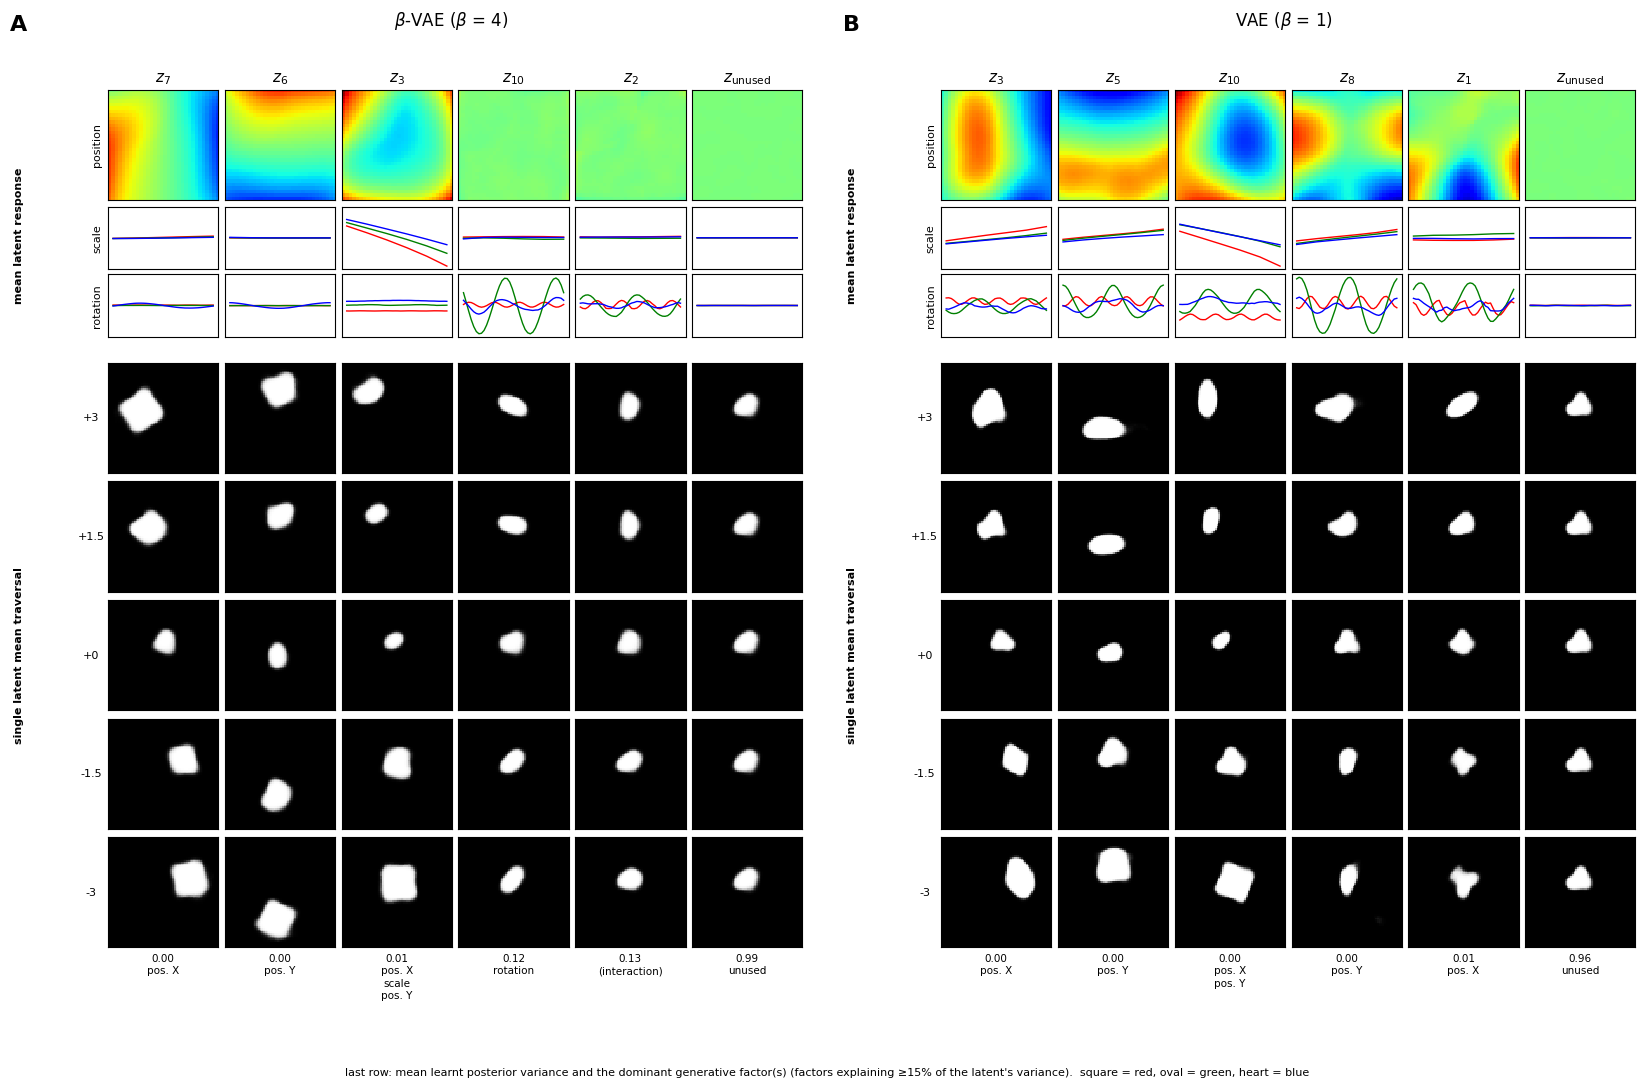

In [10]:
def select_run(panel):
    cands = [r for (p, _), r in runs.items() if p == panel]
    return max(cands, key=lambda r: r["metric"][0])

idx_seed = int(np.ravel_multi_index(CFG["seed_image_factors"], FACTOR_SIZES))
selected = {}
for panel in CFG["betas"]:
    r = select_run(panel)
    all_ids = list(range(CFG["latent_dim"]))
    r["traversals"] = dict(zip(all_ids, np.moveaxis(
        latent_traversals(r["model"], idx_seed, all_ids, CFG["traversal_values"]), 1, 0)))
    selected[panel] = r
    print(f"panel {panel}: beta={r['beta']:g}, seed={r['seed']}, metric={100 * r['metric'][0]:.2f}%")

fig7 = plot_figure7(selected["A"], selected["B"], path=os.path.join(OUT_DIR, "figure7AB.png"))

Supplementary: the same analysis for **all 10 latents** of each model, ordered by variance, so that no column is hidden.

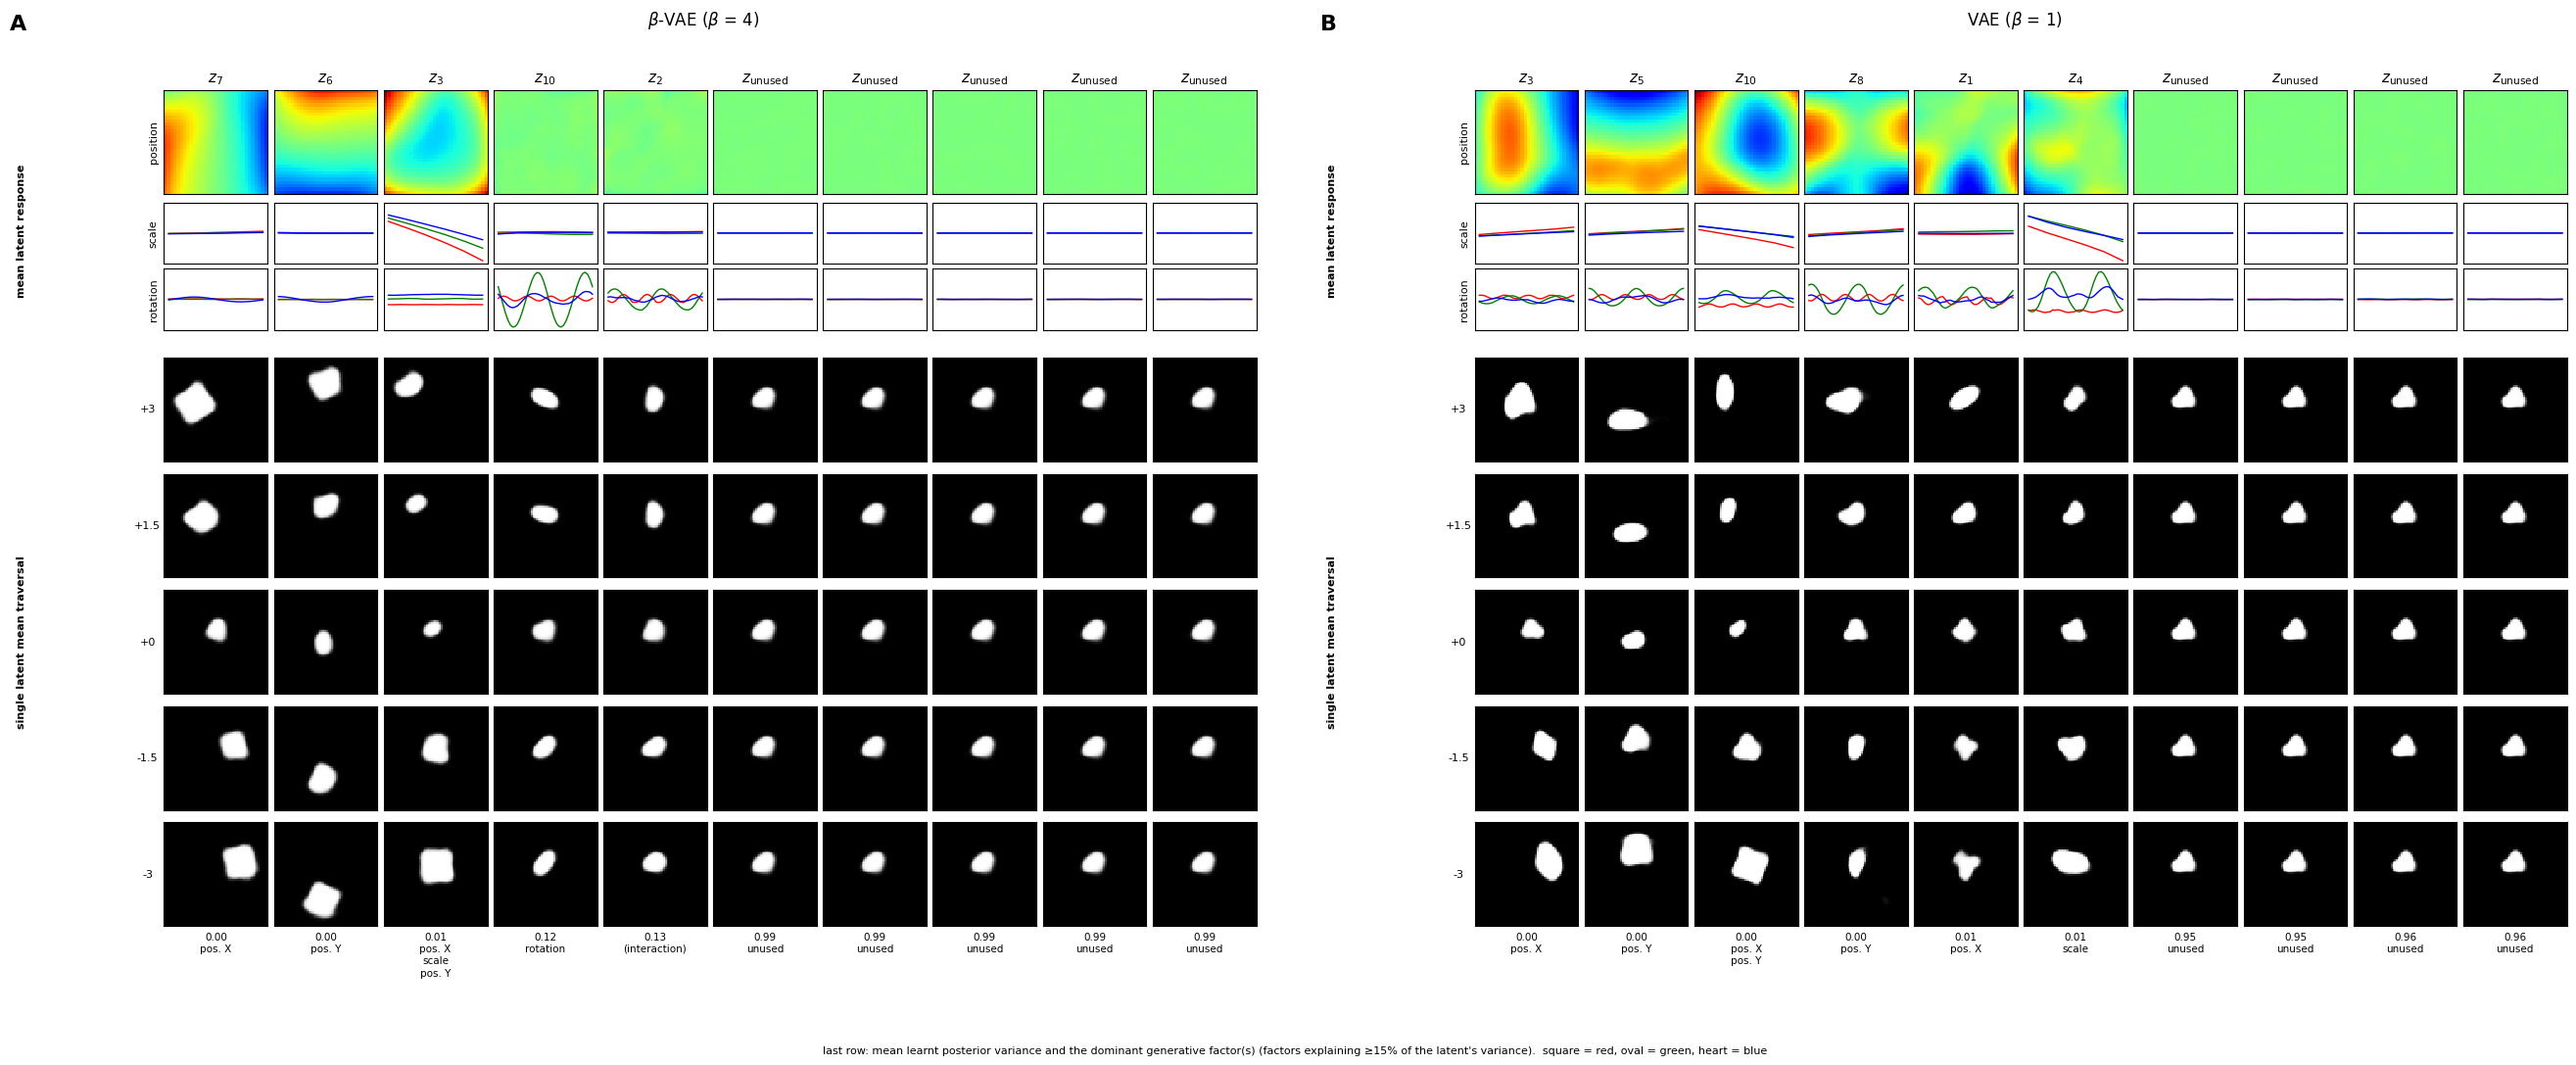

In [11]:
fig7_all = plot_figure7(selected["A"], selected["B"], path=os.path.join(OUT_DIR, "figure7AB_all_latents.png"),
                        cols_mode="all")

## 9. Quantitative check of the paper's qualitative claims
Claims made in Sec. 4.2 about Fig. 7:
1. **β-VAE (A):** separate latents encode pos X, pos Y and scale. Two latents encode rotation, behaving like cos/sin.
   Each rotation latent oscillates once per 2π for the heart, twice for the oval and four times for the square
   (the shapes' rotational symmetries). The remaining latents are unused (σ² ≈ 1).
2. **VAE (B):** most latents encode two or more generative factors.

The table gives the fraction of each latent's variance explained by each factor.


=== A: beta-VAE (beta=4) ===
 latent  mean σ²     shape     scale  rotation    pos. X    pos. Y   label
     z7    0.002      0.00      0.00      0.00      0.87      0.01   pos. X
     z6    0.002      0.00      0.00      0.00      0.01      0.91   pos. Y
     z3    0.008      0.06      0.27      0.00      0.28      0.21   pos. X + scale + pos. Y
    z10    0.117      0.00      0.00      0.57      0.00      0.00   rotation   rotation cycles per 2π (square, oval, heart) = (4, 2, 2)
     z2    0.126      0.00      0.00      0.10      0.00      0.00   (interaction)
     z9    0.988      0.00      0.00      0.02      0.02      0.01   unused
     z8    0.990      0.00      0.01      0.01      0.03      0.02   unused
     z4    0.992      0.00      0.00      0.01      0.01      0.01   unused
     z1    0.992      0.00      0.00      0.03      0.02      0.01   unused
     z5    0.992      0.00      0.00      0.01      0.01      0.01   unused
informative latents: 5 | mean purity (largest frac

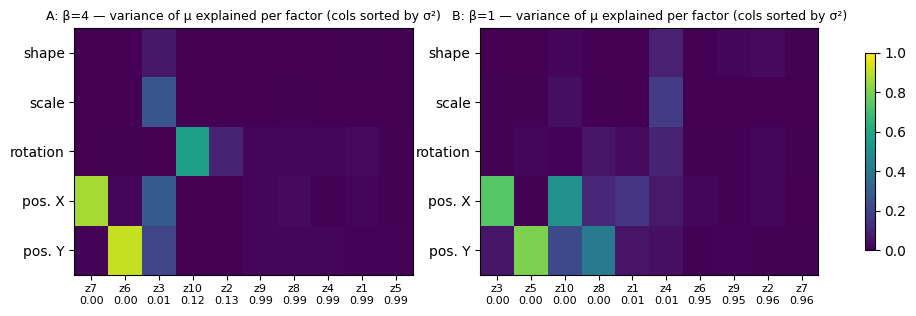

In [12]:
statsA = summarize_model(selected["A"], f"A: beta-VAE (beta={selected['A']['beta']:g})")
statsB = summarize_model(selected["B"], f"B: VAE (beta={selected['B']['beta']:g})")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, panel in zip(axes, ["A", "B"]):
    r = selected[panel]
    order = np.argsort(r["mean_var"])
    frac = factor_selectivity(r["mu"])[:, order]
    im = ax.imshow(frac, cmap="viridis", vmin=0, vmax=1, aspect="auto")
    ax.set_yticks(range(5)); ax.set_yticklabels(FACTOR_NAMES)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels([f"z{j + 1}\n{r['mean_var'][j]:.2f}" for j in order], fontsize=8)
    ax.set_title(f"{panel}: β={r['beta']:g} — variance of μ explained per factor (cols sorted by σ²)", fontsize=9)
fig.colorbar(im, ax=axes, shrink=0.8)
fig.savefig(os.path.join(OUT_DIR, "factor_selectivity.png"), dpi=150, bbox_inches="tight")
plt.show()

## 10. Training curves (supplementary)

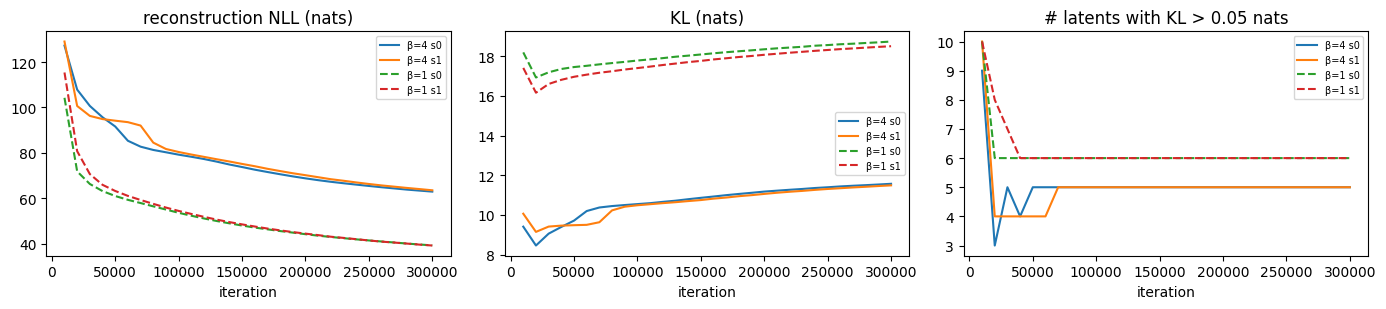

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.2))
for (panel, seed), r in runs.items():
    h = r["history"]
    if not h:
        continue
    it = [e["iter"] for e in h]
    ls = "-" if panel == "A" else "--"
    lab = f"β={r['beta']:g} s{seed}"
    axes[0].plot(it, [e["rec"] for e in h], ls, label=lab)
    axes[1].plot(it, [e["kl"] for e in h], ls, label=lab)
    axes[2].plot(it, [np.sum(np.array(e["kl_per_dim"]) > 0.05) for e in h], ls, label=lab)
axes[0].set_title("reconstruction NLL (nats)"); axes[1].set_title("KL (nats)")
axes[2].set_title("# latents with KL > 0.05 nats")
for ax in axes:
    ax.set_xlabel("iteration"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "training_curves.png"), dpi=120); plt.show()

with open(os.path.join(OUT_DIR, "results.json"), "w") as f:
    json.dump({f"{p}_seed{s}": dict(beta=r["beta"], seed=s, metric_mean=r["metric"][0], metric_std=r["metric"][1],
                                    mean_var=r["mean_var"].tolist()) for (p, s), r in runs.items()}, f, indent=1)